# Character-level MLP language model (Bengio et al., 2003)

A neural probabilistic language model in the style of [Bengio, Ducharme, Vincent & Jauvin (2003)](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf), applied to **characters** instead of words: look up a learned embedding for each of the previous 5 characters, concatenate, pass through a `tanh` hidden layer, and softmax over the next character.

Changes from the paper: mini-batches of 1024, **heavy-ball momentum** with a ramped β, step learning-rate decay, and an L2 penalty on the hidden weights.

All code and outputs are from the original Colab run. See `README.md` (top level and in this folder) for the full write-up and the mapping to the paper's equations.

In [ ]:
import torch
import torch.nn.functional as F
import random

## 1. Data and vocabulary

32,033 names. 26 letters plus `.` as the start/end token (index 0).

In [ ]:
# In Colab this was loaded from Google Drive:
#   from google.colab import drive
#   drive.mount('/content/drive')
#   words = open('/content/drive/MyDrive/names.txt', 'r').read().splitlines()
words = open('../data/names.txt', 'r').read().splitlines()

In [ ]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.']=0
itos = {i:s for s, i in stoi.items()}

## 2. Dataset: sliding context window (`block_size = 5`)

Every character becomes one training example: the 5 preceding characters (left-padded with `.`) → the character itself. `emma` gives `.....→e`, `....e→m`, `...em→m`, `..emm→a`, `.emma→.`.

80 / 10 / 10 split into train / val / test **by name**, so no name appears in two splits.

> ⚠️ `random.seed(42)` is set but `words` is never shuffled. `names.txt` is roughly ordered by popularity, so val and test are the rare-name tail of the file. They are a harder distribution than train: a bigram probe scores 2.59 on this val set vs 2.45 on a shuffled split. Part of the train/val gap below comes from this shift, not from overfitting.

In [ ]:
def build_dataset(words):
  block_size = 5
  X, Y = [],[]
  for word in words:
    context = [0]*block_size
    for ch in word+'.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]
  X = torch.tensor(X)
  Y = torch.tensor(Y)
  return X, Y

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
random.seed(42)
Xtr, Ytr = build_dataset(words[:n1])
Xval, Yval = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[n2:])

## 3. Parameters

| Tensor | Shape | Paper | Role |
|---|---|---|---|
| `C` | 27 × 10 | `C` (\|V\| × m) | embedding table, m = 10 |
| `W1`, `b1` | 50 × 500, 500 | `H`, `d` | hidden layer, input = 5 × 10 concatenated |
| `W2`, `b2` | 500 × 27, 27 | `U`, `b` | output logits |

No direct input→output connection (the paper's optional `W`). 39,297 parameters in total.

In [ ]:
C = torch.randn((27, 10), requires_grad=True)
W1 = torch.randn((50, 500), requires_grad=True)
b1 = torch.randn(500, requires_grad=True)
W2 = torch.randn((500, 27), requires_grad=True)
b2 = torch.randn(27, requires_grad=True)
parameters = [C, W1, b1, W2, b2]

In [ ]:
sum(p.nelement() for p in parameters)

39297

In [ ]:
lri = torch.linspace(-2, 0, 1000)
lrs = 10**lri
lrs = torch.tensor(lrs)

/tmp/ipykernel_2044/1343693703.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  lrs = torch.tensor(lrs)


## 4. Training

(`lrs` above is left over from the learning-rate sweep in `rough/`; it is not used here.)

**Forward:** `logits = tanh(C[X].view(-1, 50) @ W1 + b1) @ W2 + b2`. This is the paper's `y = b + U tanh(d + Hx)` with `W = 0`.

**Loss:** cross-entropy (mean NLL) + `0.001·ΣW1²` + `0.001**ΣW2²`.

**Optimiser:** heavy-ball momentum, `v ← βv + g`, `θ ← θ − lr·v`. Every 10k steps (starting at step 0), `lr` halves (floor 2e-4) and β rises by 0.01 (cap 0.95). So `lr` goes 0.16 → 0.0003 and β goes 0.86 → 0.95.

> ⚠️ Notes on this cell, explained in the README:
> - `0.001**(W2**2).sum()` is a power, not a product. ΣW2² is ≈ 13,500 at init and still thousands at the end, so the term underflows to exactly 0 and **W2 gets no weight decay**.
> - The printed "loss" includes the L2 penalty. At step 0 it is 68 = 43 cross-entropy + 25 penalty, so it is not directly comparable to the validation cross-entropy.
> - The unscaled `randn` init saturates `tanh`. Combined with a large early effective step (`lr/(1−β)` ≈ 1.1), this causes the spikes in the first ~5k steps.

In [ ]:
train_loss = []
val_loss = []
min_loss = 1e9
best_W1 = None
best_W2 = None
best_b1 = None
best_b2 = None
best_C = None
lr = 0.32
beta = 0.85 # momentum coefficient
C = torch.randn((27, 10), requires_grad=True)
W1 = torch.randn((50, 500), requires_grad=True) # Changed from (8, 200) to (12, 200) to match 3 * 4
b1 = torch.randn(500, requires_grad=True)
W2 = torch.randn((500, 27), requires_grad=True)
b2 = torch.randn(27, requires_grad=True)
parameters = [C, W1, b1, W2, b2] # Redefine parameters list with the active variables
velocities = [torch.zeros_like(p) for p in parameters]
prev_loss = 1e8
for i in range(100000):
  #constructing minibatch
  indices = torch.randint(0, Xtr.shape[0], (1024,))
  #forward pass
  emb = C[Xtr[indices]]
  h1 = emb.view(-1, 50)@W1 + b1 # Changed from .view(-1, 8) to .view(-1, 12)
  h1 = h1.tanh()
  logits = h1@W2 + b2
  loss = F.cross_entropy(logits, Ytr[indices]) + 0.001*(W1**2).sum() + 0.001**(W2**2).sum()
  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update weights
  for p, v in zip(parameters, velocities):
    # Update velocity
    v.data = beta * v.data + p.grad.data
    # Update weights
    p.data -= lr * v.data

  if abs(loss-prev_loss)<1e-8:
    break

  if i%1000==0:
    train_loss.append(loss)
    emb = C[Xval]
    h1 = emb.view(-1, 50)@W1 + b1
    h1 = h1.tanh()
    logits = h1@W2 + b2
    loss_val = F.cross_entropy(logits, Yval)
    val_loss.append(loss_val)
    print(f"loss at {i}: {loss.item():.4f}")

  if i%10000==0:
    lr/=2
    lr = max(lr, 0.0002)
    beta+=0.01
    beta = min(0.95, beta)


  # if loss<min_loss:
  #   min_loss = loss
  #   best_W1 = W1
  #   best_b1 = b1
  #   best_W2 = W2
  #   best_b2 = b2
  #   best_C = C

  prev_loss = loss


loss at 0: 68.0286
loss at 1000: 30.1919
loss at 2000: 49.6702
loss at 3000: 45.1433
loss at 4000: 6.3647
loss at 5000: 5.5367
loss at 6000: 2.3457
loss at 7000: 2.1265
loss at 8000: 2.2522
loss at 9000: 2.1746
loss at 10000: 2.1413
loss at 11000: 2.0827
loss at 12000: 2.1447
loss at 13000: 2.0552
loss at 14000: 2.0547
loss at 15000: 2.0650
loss at 16000: 2.0420
loss at 17000: 2.1119
loss at 18000: 2.0288
loss at 19000: 2.0924
loss at 20000: 2.0912
loss at 21000: 1.9576
loss at 22000: 2.0399
loss at 23000: 2.0374
loss at 24000: 1.9680
loss at 25000: 1.9707
loss at 26000: 2.0016
loss at 27000: 2.0287
loss at 28000: 1.9360
loss at 29000: 1.9992
loss at 30000: 1.9767
loss at 31000: 2.0112
loss at 32000: 1.8942
loss at 33000: 1.9346
loss at 34000: 1.9790
loss at 35000: 1.9303
loss at 36000: 1.9835
loss at 37000: 1.9252
loss at 38000: 2.0080
loss at 39000: 1.9002
loss at 40000: 1.9102
loss at 41000: 1.9364
loss at 42000: 1.9064
loss at 43000: 1.8661
loss at 44000: 1.9222
loss at 45000: 1.90

## 5. Evaluation

The last mini-batch training loss (1.88, including the penalty) and the full **validation** cross-entropy: **2.238 nats/char**, i.e. perplexity e^2.238 ≈ 9.4 (uniform = 27). The comment says "test set", but this cell evaluates `Xval`; the test split is never evaluated in this notebook.

In [ ]:
print(prev_loss.item())
#loss on test set
emb = C[Xval]
h1 = emb.view(-1, 50)@W1 + b1
h1 = h1.tanh()
logits = h1@W2 + b2
loss = F.cross_entropy(logits, Yval)
loss.item()

1.8826203346252441


2.2382946014404297

Train (blue, includes the L2 penalty) vs validation (orange) every 1,000 steps. Validation flattens near 2.24 after about 60k steps, as `lr` decays.

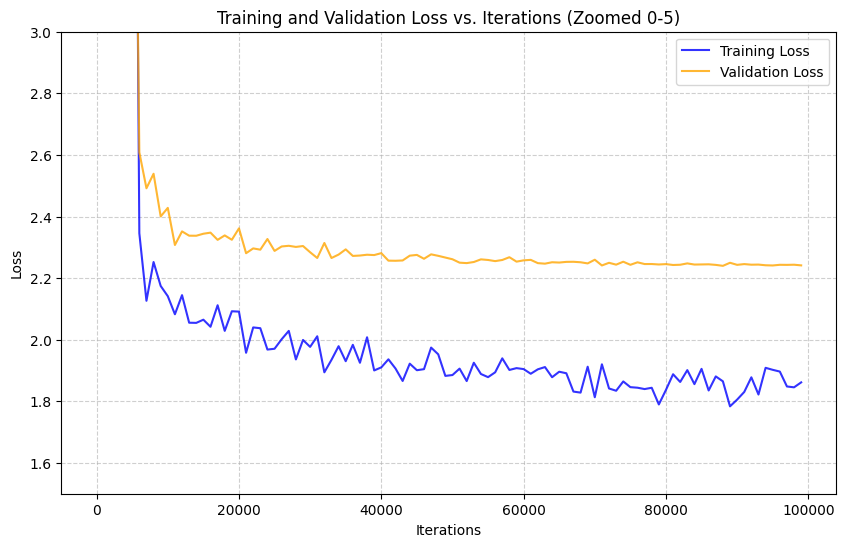

In [ ]:
import matplotlib.pyplot as plt

# Fallback check if training loop hasn't run yet
if 'train_loss' not in globals() or 'val_loss' not in globals():
    print("Warning: 'train_loss' or 'val_loss' not found. Please run cell NCuNBm3mYwkj first.")
    train_loss = []
    val_loss = []

if len(train_loss) > 0:
    # Convert PyTorch tensors to standard Python floats
    train_loss_plots = [t.item() if hasattr(t, 'item') else t for t in train_loss]
    val_loss_plots = [v.item() if hasattr(v, 'item') else v for v in val_loss]

    # Calculate iterations matching each recorded point (recorded every 1000 iterations)
    iterations = [i * 1000 for i in range(len(train_loss_plots))]

    plt.figure(figsize=(10, 6))
    plt.plot(iterations, train_loss_plots, label='Training Loss', color='blue', alpha=0.8)
    plt.plot(iterations, val_loss_plots, label='Validation Loss', color='orange', alpha=0.8)

    # Set y-axis limit to zoom in clearly on the main training phase
    plt.ylim(1.5, 3)

    plt.title('Training and Validation Loss vs. Iterations (Zoomed 0-5)')
    plt.xlabel('Iterations')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()
else:
    print("No recorded losses found to plot. Run your training cell to populate the logs!")

In [ ]:
print(min(loss for loss in val_loss))

tensor(2.2399, grad_fn=<NllLossBackward0>)


## 6. Sampling

Start from `.....`, sample the next character from the softmax, slide the window, and stop at `.`. Compared with the bigram model in [`designing-bigram`](https://github.com/tusharchandra19/designing-bigram), five characters of context give names that look much more real: `kendalynn`, `raelynn`, `viyanna`, `rhileigh`.

In [ ]:
for i in range(20):
  word = []
  block_size = 5
  context = [0] * block_size # Start with padding characters ('.')
  while True:
    # FIX: Query using the entire context of 5 characters, not just the single index
    emb = C[torch.tensor([context])] # shape (1, 5, 10)
    h1 = emb.view(-1, 50)@W1 + b1 # shape (1, 50) @ (50, 500) -> (1, 500)
    h1 = h1.tanh()
    logits = h1@W2 + b2
    probs = F.softmax(logits, dim=1) # Apply softmax across character logits dimension

    # Sample next character index
    ix = torch.multinomial(probs, num_samples=1, replacement=True).item()
    ch = itos[ix]
    if ix == 0:
      break
    word.append(ch)

    # Update context by sliding the window
    context = context[1:] + [ix]

  print(''.join(word))

jester
shya
maileya
styn
kaseen
kendalynn
sirwin
suzlay
viyanna
elianna
aria
dalvie
rhileigh
makenz
kayler
kord
raelynn
lamon
ayleen
haklane
